# 05 — Walk-Forward Backtest

Monthly target weights from notebook 04 are traded at each month-end close and held to the next month-end. Daily simulation on EUR returns:

* **Drift:** $w_{i,d+1} = w_{i,d}(1+r_{i,d}) / (1+r_{p,d})$ between rebalances.
* **Turnover and costs:** $TO_t=\sum_i |w^{target}_{i,t}-w^{drifted}_{i,t}|$, $TC_t = c\cdot TO_t$ with $c$ = 10bp (sensitivity 0–50bp). The initial build from cash is not charged.
* **Cash and leverage:** $1-\sum_i w_i$ earns (or, if negative, pays) the EUR overnight rate (EONIA → €STR, ACT/360).
* **Volatility-targeted versions (\*)**: risk-based targets are scaled by $L_t=\sigma^{ex-ante}_{60/40,t}/\sigma^{ex-ante}_{strategy,t}$ (cap 5×), financed at the overnight rate — how risk parity is run in practice.
* Out of sample from **2010-05-03 to 2026-09-30**; covariance input GARCH-CCC unless stated; every estimator from notebook 03 is re-run in section 3.

Engine checks live in `tests/test_backtest.py` (drift-implied turnover, financing, decision-date timing, and a look-ahead test: forecasts up to 2015-11 are identical with or without later data).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import backtest as B, data_loader as dl, optimize as O, risk as K, universe as U

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
PROC = ROOT / "data" / "processed"
daily = pd.read_csv(PROC / "asset_returns_eur_daily.csv", index_col=0, parse_dates=True)[U.ASSETS].loc["2010-04-01":]
weekly = pd.read_csv(PROC / "asset_returns_eur_weekly.csv", index_col=0, parse_dates=True)[U.ASSETS].dropna()
fc = K.load_forecasts(PROC / "cov_forecasts.npz")
paths = O.weight_paths(fc, weekly, cache_dir=PROC / "weights")                                   # notebook 04
by_est = O.covariance_rule_paths(fc, K.ESTIMATORS, cache_dir=PROC / "weights" / "by_estimator")
cash = B.daily_cash_returns(daily.index, dl.load_short_rates()["EUR"])
COST = 10.0                                    # bp per unit traded (one-way notional)
S_main = fc["cov1w"]["GARCH-CCC"]

## 1. Main results (10bp costs)

In [2]:
runs, stats = {}, {}
for m in O.METHODS:
    runs[m] = B.run_backtest(daily, paths[m], cash, COST)
for m in ["MinVar", "RiskParity", "CVaR"]:
    lev = B.vol_target_leverage(paths[m], S_main, paths["60/40"])
    runs[m + "*"] = B.run_backtest(daily, paths[m], cash, COST, leverage=lev)
for k, r in runs.items():
    stats[k] = B.perf_stats(r.net, cash, r.turnover, r.cost) | {"avg leverage": r.leverage.mean()}
nets = pd.DataFrame({k: r.net for k, r in runs.items()})
print(f"{nets.index[0]:%Y-%m-%d} → {nets.index[-1]:%Y-%m-%d}, {len(nets)} days")
main = pd.DataFrame(stats).T
main

2010-05-03 → 2026-09-30, 4272 days


,ann. return,ann. vol,Sharpe,Sortino,max drawdown,Calmar,VaR95 1d,ES95 1d,turnover p.a.,cost p.a.,avg leverage
EW,0.049,0.059,0.712,1.001,-0.137,0.355,0.005,0.009,0.234,0.000,1.000
60/40,0.084,0.098,0.789,1.104,-0.201,0.416,0.009,0.015,0.206,0.000,1.000
MinVar,0.008,0.021,0.107,0.149,-0.118,0.068,0.002,0.003,1.443,0.001,1.000
RiskParity,0.017,0.025,0.459,0.648,-0.090,0.194,0.002,0.004,0.932,0.001,1.000
CVaR,0.014,0.024,0.328,0.466,-0.125,0.111,0.002,0.003,0.757,0.001,1.000
MV-hist,0.082,0.102,0.746,1.036,-0.158,0.519,0.010,0.016,2.780,0.003,1.000
MinVar*,0.015,0.095,0.140,0.193,-0.490,0.031,0.009,0.014,8.245,0.008,4.479
RiskParity*,0.057,0.099,0.537,0.751,-0.325,0.176,0.009,0.014,5.066,0.005,4.167
CVaR*,0.030,0.093,0.289,0.403,-0.418,0.071,0.009,0.013,6.012,0.006,3.873


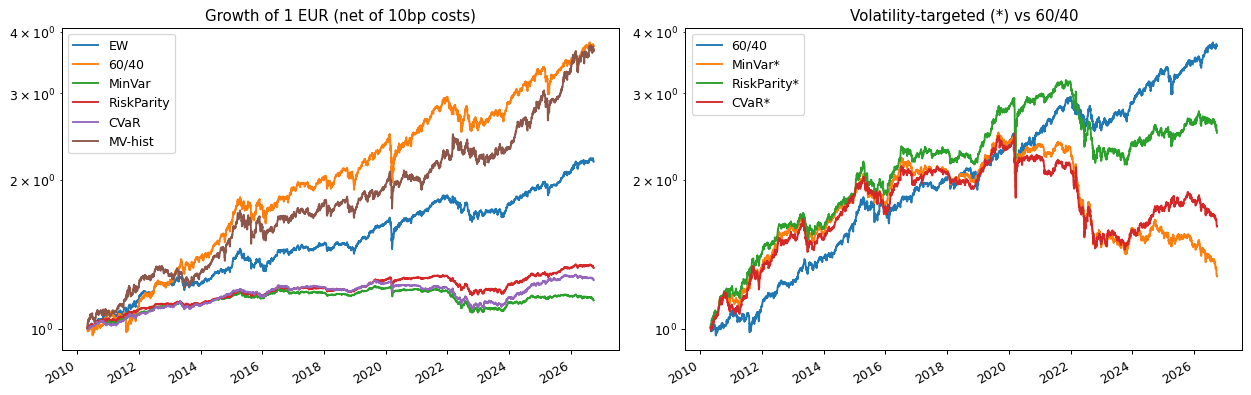

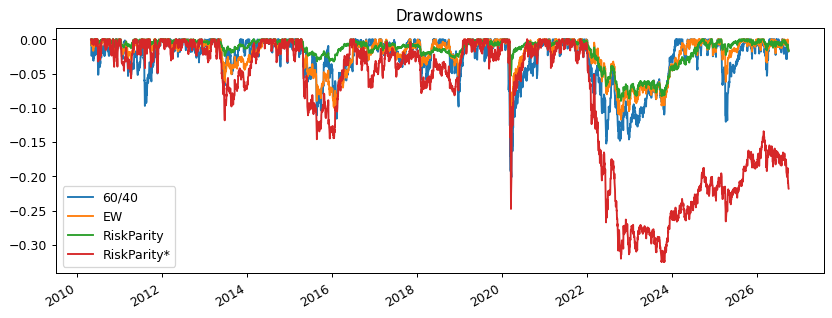

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(1 + nets[O.METHODS]).cumprod().plot(ax=ax[0], logy=True, title="Growth of 1 EUR (net of 10bp costs)")
(1 + nets[["60/40", "MinVar*", "RiskParity*", "CVaR*"]]).cumprod().plot(ax=ax[1], logy=True, title="Volatility-targeted (*) vs 60/40")
plt.tight_layout(); plt.show()
w = (1 + nets[["60/40", "EW", "RiskParity", "RiskParity*"]]).cumprod()
(w / w.cummax() - 1).plot(title="Drawdowns"); plt.show()

**Is any Sharpe ratio significantly different from 60/40?** Jobson–Korkie test with the Memmel (2003) correction on monthly excess returns.

In [4]:
cm = (1 + cash.reindex(nets.index)).resample("ME").prod() - 1
mex = (1 + nets).resample("ME").prod().sub(1).sub(cm, axis=0)
pd.DataFrame({k: dict(zip(["z", "p-value"], B.memmel_test(mex[k], mex["60/40"]))) for k in nets.columns if k != "60/40"}).T

,z,p-value
EW,-1.151,0.250
MinVar,-3.942,0.000
RiskParity,-2.654,0.008
CVaR,-2.632,0.008
MV-hist,-0.045,0.964
MinVar*,-3.695,0.000
RiskParity*,-2.180,0.029
CVaR*,-2.709,0.007


## 2. Calendar years and the 2022 stock–bond break

In [5]:
yr = (1 + nets).resample("YE").prod() - 1
yr.index = yr.index.year
(yr * 100).round(1).T

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
EW,7.800,6.500,7.500,-0.400,7.800,1.500,7.000,2.800,-3.000,13.400,5.000,8.800,-10.100,7.100,7.600,7.300,5.400
60/40,6.700,4.200,11.400,12.700,17.300,8.100,8.100,4.500,-1.400,19.700,6.200,17.500,-14.000,13.700,14.800,5.300,7.700
MinVar,3.500,3.700,4.000,-0.200,4.100,-0.600,2.800,-0.300,-0.800,2.800,-0.200,-0.900,-9.400,4.700,2.600,0.300,-2.000
RiskParity,4.800,4.200,2.900,-0.200,3.800,0.300,3.100,0.400,-1.200,5.000,1.400,0.800,-8.200,4.800,4.400,3.200,0.100
CVaR,2.300,4.400,4.000,0.000,6.100,-1.000,3.100,0.800,-1.100,2.800,-0.800,-1.300,-8.500,4.600,6.400,3.600,-1.700
MV-hist,8.700,11.600,5.700,1.000,17.700,5.600,4.000,5.800,-3.100,12.700,5.100,13.300,-5.400,6.400,23.400,15.800,10.500
MinVar*,16.800,15.300,19.800,-3.900,19.400,-3.100,16.900,-0.700,-1.700,16.200,-0.400,-2.200,-36.600,8.300,-1.100,-6.300,-13.300
RiskParity*,21.000,18.100,13.800,-2.000,17.600,0.900,18.100,2.500,-2.900,25.300,7.200,5.800,-30.400,8.200,4.400,4.500,-3.800
CVaR*,11.500,18.400,17.400,-2.500,23.400,-5.800,13.800,3.600,-2.600,15.200,-3.600,-5.000,-30.200,6.400,10.300,3.700,-10.800


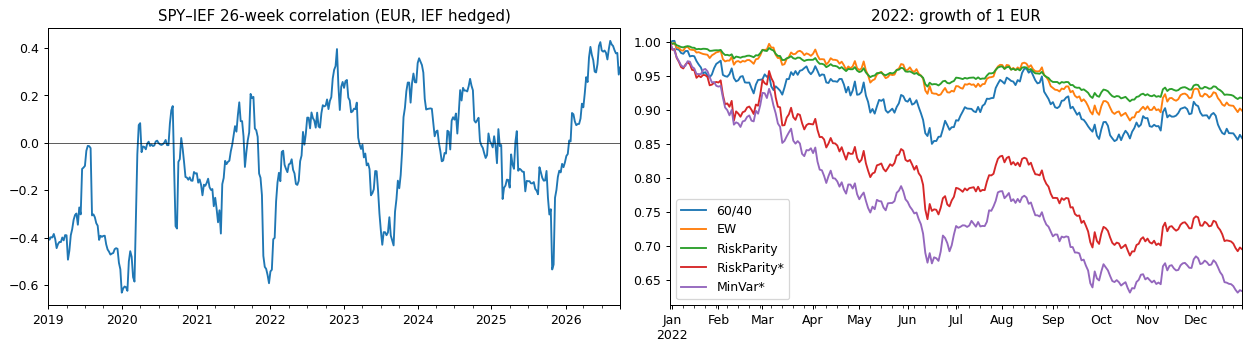

In [6]:
corr = weekly["SPY"].rolling(26).corr(weekly["IEF"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
corr.loc["2019":].plot(ax=ax[0], title="SPY–IEF 26-week correlation (EUR, IEF hedged)"); ax[0].axhline(0, color="k", lw=0.5)
sub = (1 + nets.loc["2021-12-31":"2022-12-31", ["60/40", "EW", "RiskParity", "RiskParity*", "MinVar*"]]).cumprod()
sub.plot(ax=ax[1], title="2022: growth of 1 EUR"); plt.tight_layout(); plt.show()

## 3. Does a better covariance forecast give a better portfolio?

Same rules, five covariance estimators (raw, 10bp costs).

In [7]:
est_rows = {}
for (e, m), w in by_est.items():
    r = B.run_backtest(daily, w, cash, COST)
    s = B.perf_stats(r.net, cash, r.turnover, r.cost)
    est_rows[(m, e)] = {"ann. vol": s["ann. vol"], "Sharpe": s["Sharpe"], "turnover p.a.": s["turnover p.a."],
                        "cost p.a.": s["cost p.a."], "max drawdown": s["max drawdown"]}
est_tab = pd.DataFrame(est_rows).T
est_tab

,,ann. vol,Sharpe,turnover p.a.,cost p.a.,max drawdown
MinVar,Sample,0.021,0.200,0.113,0.000,-0.102
RiskParity,Sample,0.026,0.522,0.134,0.000,-0.090
MinVar,Rolling,0.022,0.254,0.412,0.000,-0.113
RiskParity,Rolling,0.025,0.523,0.295,0.000,-0.084
MinVar,EWMA,0.022,0.159,0.776,0.001,-0.114
RiskParity,EWMA,0.025,0.447,0.535,0.001,-0.088
MinVar,LedoitWolf,0.022,0.206,0.374,0.000,-0.128
RiskParity,LedoitWolf,0.025,0.522,0.280,0.000,-0.086
MinVar,GARCH-CCC,0.021,0.107,1.443,0.001,-0.118
RiskParity,GARCH-CCC,0.025,0.459,0.932,0.001,-0.090


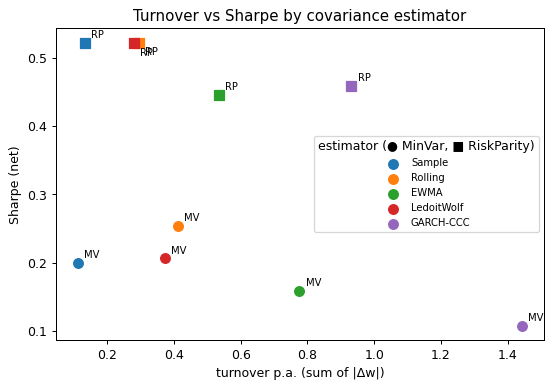

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = dict(zip(K.ESTIMATORS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
for j, ((m, e), row) in enumerate(est_tab.iterrows()):
    ax.scatter(row["turnover p.a."], row["Sharpe"], marker="o" if m == "MinVar" else "s", s=60, color=colors[e],
               label=e if m == "MinVar" else None)
    ax.annotate("MV" if m == "MinVar" else "RP", (row["turnover p.a."], row["Sharpe"]), fontsize=8,
                xytext=(5, -10 if j % 4 == 3 else 4), textcoords="offset points")
ax.legend(title="estimator (● MinVar, ■ RiskParity)", fontsize=8)
ax.set_xlabel("turnover p.a. (sum of |Δw|)"); ax.set_ylabel("Sharpe (net)"); ax.set_title("Turnover vs Sharpe by covariance estimator"); plt.show()

## 4. Cost sensitivity

In [9]:
costs = [0, 5, 10, 25, 50]
sens = {}
for k in ["EW", "60/40", "MinVar", "RiskParity", "CVaR", "MV-hist", "RiskParity*"]:
    base = k.rstrip("*"); lev = runs[k].leverage if k.endswith("*") else None
    sens[k] = {f"{c}bp": B.perf_stats(B.run_backtest(daily, paths[base], cash, c, leverage=lev).net, cash)["Sharpe"] for c in costs}
pd.DataFrame(sens).T

,0bp,5bp,10bp,25bp,50bp
EW,0.716,0.714,0.712,0.706,0.697
60/40,0.791,0.790,0.789,0.786,0.780
MinVar,0.172,0.140,0.107,0.009,-0.154
RiskParity,0.496,0.477,0.459,0.404,0.313
CVaR,0.358,0.343,0.328,0.282,0.206
MV-hist,0.772,0.759,0.746,0.706,0.639
RiskParity*,0.587,0.562,0.537,0.463,0.338


## 5. Monthly vs quarterly rebalancing

In [10]:
freq_rows = {}
for m in ["MinVar", "RiskParity", "CVaR", "MV-hist"]:
    q = paths[m][(paths[m].index.month % 3 == 0) | (paths[m].index == paths[m].index[0])]
    for label, tg in [("monthly", paths[m]), ("quarterly", q)]:
        r = B.run_backtest(daily, tg, cash, COST, end=nets.index[-1])
        s = B.perf_stats(r.net, cash, r.turnover, r.cost)
        freq_rows[(m, label)] = {k: s[k] for k in ["ann. return", "ann. vol", "Sharpe", "turnover p.a.", "cost p.a."]}
pd.DataFrame(freq_rows).T

ann. return  ann. vol  Sharpe  turnover p.a.  cost p.a.
MinVar     monthly          0.008     0.021   0.107          1.443      0.001
           quarterly        0.008     0.022   0.110          0.772      0.001
RiskParity monthly          0.017     0.025   0.459          0.932      0.001
           quarterly        0.017     0.025   0.432          0.517      0.001
CVaR       monthly          0.014     0.024   0.328          0.757      0.001
           quarterly        0.014     0.024   0.344          0.593      0.001
MV-hist    monthly          0.082     0.102   0.746          2.780      0.003
           quarterly        0.071     0.105   0.632          1.580      0.002

In [11]:
nets.to_csv(PROC / "backtest_daily_net.csv")
pd.DataFrame({k: r.gross for k, r in runs.items()}).to_csv(PROC / "backtest_daily_gross.csv")
print("saved", (PROC / "backtest_daily_net.csv").name)

saved backtest_daily_net.csv


## Takeaways

* **60/40 wins on risk-adjusted terms over 2010-05 → 2026-09** (Sharpe 0.79). Equal weight (0.71) is not significantly different (Memmel p = 0.25); **every risk-based rule is significantly worse** — MinVar 0.11, CVaR 0.33, Risk Parity 0.46 (p ≤ 0.01), and still after volatility targeting (RP\* 0.54, p = 0.03). The sample is one long equity bull market plus a bond bear market since 2021, which is exactly the environment where bond-heavy portfolios lose.
* **2022 answers the README question on diversification.** 60/40 lost 14%, EW 10%. Unlevered risk-based portfolios lost 8–9% — a large loss for a 2%-volatility portfolio. Volatility-targeted versions lost **30–37%**: at ~4× leverage on bonds, the positive stock–bond correlation and the rates shock compounded. Volatility targeting assumes the covariance matrix is stable; 2022 broke that assumption.
* **A better covariance forecast did not give a better portfolio.** GARCH-CCC, the most accurate forecaster in notebook 03, produced the *lowest* Sharpe for both MinVar (0.11 vs 0.20–0.25 for Sample/Rolling) and Risk Parity, with 7–13× the turnover of the sample covariance. For allocation, stability of the input matters more than one-step accuracy.
* **Costs matter only where turnover is high.** At 10bp the drag is ≤ 0.3% a year for unlevered rules but 0.5–0.8% for the volatility-targeted ones; MinVar's Sharpe falls to zero at 25bp. Quarterly rebalancing halves turnover at no Sharpe cost for MinVar and CVaR, but hurts MV-hist (0.75 → 0.63).
* **MV-hist matched 60/40 (p = 0.96) only through lucky equity and gold tilts** — 2.8× annual turnover and 106 changes of the largest holding (notebook 04) make it un-investable.

Next: notebook 06 — VaR/ES models and their backtests on the daily returns saved here.